# Baseline 2 — Exp09: ResNet-50 V2 (B1-matched, seed 42)

**New experiment only. Do not overwrite Exp08 or previous EfficientNet checkpoints.**

- Architecture: one shared ImageNet-1K V2 ResNet-50 backbone + independent crop (55) and disease (175) heads.
- Match Amanda's **higher_decay** B1 configuration: weight decay = `1e-3`, RandomResizedCrop bilinear, RandomRotation nearest, evaluation resize bilinear; batch size 16; crop/disease dropout 0.3/0.2; image size 224.
- Same development split, standard random-shuffle sampling, seed 42 and all 9,625 candidate pairs.
- `num_workers=4` is a throughput optimization suggested by a **single 80-batch** benchmark (27.22s, versus 35.30s at 0 workers). Recheck if Windows multiprocessing causes errors. It can change the exact sequence of augmentations; reproducibility depends on fixed code and worker settings.
- **Important methodological difference:** B1 independently picks crop/disease HM-best checkpoints; B2 uses one shared checkpoint selected by composition HM. This is a comparison of full baseline pipelines, not a perfect single-factor architecture ablation.
- This notebook DOES NOT automatically train (`RUN_STAGE1=False`), run Stage 2, or access official test data.

**Source:** a copy of the previous Baseline 2 ResNet-50 notebook with the fixed Section 5 synthetic smoke check. Use the local `model_resnet50.py`, `evaluate.py`, `splits_v2/` and `DPD_Small_dataset/` already in `C:\AML\ML_Project`.


## 1. Configuration — Exp09, B1-matched

Run Sections 1–6 once in order. Verify CUDA, image path and metadata, then explicitly set `RUN_STAGE1=True` in Section 1 and rerun **Section 1 only**, followed by Section 7. Existing outputs are protected by experiment ID checks.

Seed `42` is intentionally fixed for this single-run B1-matched experiment. Multi-seed verification should be done later in separate experiment IDs with **all other settings held fixed**. No resplitting.


In [7]:
from pathlib import Path
from dataclasses import dataclass
import copy
import gc
import json
import math
import platform
import random
import tempfile
import time

import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import DataLoader
import torchvision
from torchvision import transforms as T
from torchvision.transforms import InterpolationMode

from model_resnet50 import MultiTaskResNet50, load_resnet50_checkpoint as load_checkpoint
from evaluate import (DPDDataset, MEAN, STD, evaluate_loader, generalisation_metrics,
                      validate_development_splits, validation_transform,
                      make_candidates, require_candidate_coverage,
                      sha256_file, synthetic_self_test)

PROJECT_DIR = Path.cwd()
SPLIT_DIR = PROJECT_DIR / "splits_v2"
DATASET_ROOT = PROJECT_DIR.parent / "DPD_Small_dataset"   # Configure locally.
IMAGE_ROOT = DATASET_ROOT                # Verified local development image folder; no train/ subfolder.
OUTPUT_ROOT = PROJECT_DIR / "outputs"
RUN_STAGE1 = True   # Set True only after checking paths, teammate settings, and GPU.

CONFIG = {
    "experiment_id": "b2_resnet50_exp09_b1matched_seed42", "changed_parameter": "B1-matched ResNet50-V2: WD=1e-3, train/val interpolation aligned, 4 loader workers",
    "backbone": "resnet50", "pretrained_weights": "IMAGENET1K_V2",
    "crop_classes": 55, "disease_classes": 175, "image_size": 224,
    "batch_size": 16, "max_epochs": 30, "patience": 15, "min_delta": 1e-6,
    "backbone_lr": 1e-5, "head_lr": 1e-3, "crop_dropout": 0.3, "disease_dropout": 0.2,
    "weight_decay": 1e-3, "optimizer": "AdamW", "scheduler": "CosineAnnealingLR",
    "crop_loss_weight": 1.0, "disease_loss_weight": 1.0,
    "seed": 42, "num_workers": 4, "amp": True,
    "crop_scale": [0.85, 1.0], "flip_probability": 0.5, "vertical_flip_probability": 0.5,
    "rotation_degrees": 10, "brightness": 0.15, "contrast": 0.15,
    "interpolation": "bilinear_resize_nearest_rotation", "mean": list(MEAN), "std": list(STD),
    "candidate_mode": "all_pairs",   # Change ONLY if B1 has a different group-approved candidate rule.
    "candidate_catalog": None,       # For mode='catalog': path to agreed pair-only metadata.
}
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__, "torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available(), "device:", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
print(json.dumps(CONFIG, indent=2))

PyTorch: 2.11.0+cu128 torchvision: 0.26.0+cu128
CUDA available: True device: cuda
GPU: NVIDIA GeForce RTX 4050 Laptop GPU
{
  "experiment_id": "b2_resnet50_exp09_b1matched_seed42",
  "changed_parameter": "B1-matched ResNet50-V2: WD=1e-3, train/val interpolation aligned, 4 loader workers",
  "backbone": "resnet50",
  "pretrained_weights": "IMAGENET1K_V2",
  "crop_classes": 55,
  "disease_classes": 175,
  "image_size": 224,
  "batch_size": 16,
  "max_epochs": 30,
  "patience": 15,
  "min_delta": 1e-06,
  "backbone_lr": 1e-05,
  "head_lr": 0.001,
  "crop_dropout": 0.3,
  "disease_dropout": 0.2,
  "weight_decay": 0.001,
  "optimizer": "AdamW",
  "scheduler": "CosineAnnealingLR",
  "crop_loss_weight": 1.0,
  "disease_loss_weight": 1.0,
  "seed": 42,
  "num_workers": 4,
  "amp": true,
  "crop_scale": [
    0.85,
    1.0
  ],
  "flip_probability": 0.5,
  "vertical_flip_probability": 0.5,
  "rotation_degrees": 10,
  "brightness": 0.15,
  "contrast": 0.15,
  "interpolation": "bilinear_resize_ne

## 2. Verify the exact development metadata
Only `train_fit.csv`, `val_seen.csv`, `val_unseen.csv`, `heldout_compositions.csv`, and `split_manifest.json` are read. Checks include counts, disjoint filenames, canonical ID/name consistency, held-out compositions, concept coverage, and file hashes. No resplitting or relabelling occurs.

Expected: train 6,905 images / 313 compositions; seen validation 695 / 273; unseen validation 400 / 10. Training covers all 55 crops and 175 diseases. Image existence and decoding are checked separately on your laptop.


In [2]:
frames, split_report = validate_development_splits(SPLIT_DIR)
print(json.dumps(split_report, indent=2))
canonical_metadata = pd.concat(frames.values(), ignore_index=True)
class_mappings = {
    task: {str(int(row[0])): str(row[1]) for row in
           canonical_metadata[[f"{task}_id", f"{task}_name"]].drop_duplicates().itertuples(index=False, name=None)}
    for task in ("crop", "disease", "composition")
}
composition_mapping = canonical_metadata[
    ["composition_id", "crop_id", "disease_id", "composition_name"]
].drop_duplicates().sort_values("composition_id").to_dict(orient="records")
print("Original IDs retained; no new class numbering.")


{
  "counts": {
    "train_fit": 6905,
    "val_seen": 695,
    "val_unseen": 400
  },
  "coverage": {
    "train_fit": {
      "crop_id": 55,
      "disease_id": 175,
      "composition_id": 313
    },
    "val_seen": {
      "crop_id": 55,
      "disease_id": 155,
      "composition_id": 273
    },
    "val_unseen": {
      "crop_id": 10,
      "disease_id": 8,
      "composition_id": 10
    }
  },
  "sha256": {
    "train_fit.csv": "fe02d6099c002b10e5a428c2260d5de50f3e677d3b7454216b2a340e55c2a377",
    "val_seen.csv": "ab8d18a13b28fd5a7b9ea531b8ffbdcf4174fd6920337ee9f1a726129390daf5",
    "val_unseen.csv": "b9eae2a57d8331d97636f4e8a8e32bc2e81704d7180fdac22ae923273aadec67",
    "heldout_compositions.csv": "437f57924eef3e5788ed0993caddd969e08f9f86add64791d944425f4bddfe7f",
    "split_manifest.json": "c120d065677e37db6d00880104684c0cd70ccd1c0774ec4aac2eb4b4b0889df8"
  },
  "image_paths_checked": false
}
Original IDs retained; no new class numbering.


## 3. Preprocessing — aligned to Amanda's B1 notebook

Train: `RandomResizedCrop(224, scale=(0.85,1.0))` (bilinear), H/V flip p=.5, rotation +/-10 deg (nearest), brightness/contrast=.15; ImageNet normalization. Validation: `Resize(256)` bilinear, `CenterCrop(224)`, ToTensor, ImageNet normalization. Same all-pair candidate scoring policy (9,625).

For a separate 320-training ablation later, adjust **both** training and evaluation size and use a new experiment ID. Do not call this 224-trained experiment a 320-trained run.


In [3]:
def training_transform(config):
    return T.Compose([
        T.RandomResizedCrop(config["image_size"], scale=tuple(config["crop_scale"]),
                            interpolation=InterpolationMode.BILINEAR),
        T.RandomHorizontalFlip(p=config["flip_probability"]),
        T.RandomVerticalFlip(p=config["vertical_flip_probability"]),
        T.RandomRotation(config["rotation_degrees"], interpolation=InterpolationMode.NEAREST),
        T.ColorJitter(brightness=config["brightness"], contrast=config["contrast"]),
        T.ToTensor(), T.Normalize(MEAN, STD),
    ])

def evaluation_transform(image_size):
    resized = round(image_size * 256 / 224)
    return T.Compose([
        T.Resize(resized, interpolation=InterpolationMode.BILINEAR),
        T.CenterCrop(image_size),
        T.ToTensor(), T.Normalize(MEAN, STD),
    ])


candidates = make_candidates(CONFIG["candidate_mode"], CONFIG["candidate_catalog"])
require_candidate_coverage(candidates, list(frames.values()))
print(f"Candidate mode: {CONFIG['candidate_mode']}; {len(candidates):,} global candidate pairs")
if CONFIG["candidate_mode"] == "all_pairs":
    print("PROVISIONAL: confirm the same candidate policy with Baseline 1 before comparing results.")

Candidate mode: all_pairs; 9,625 global candidate pairs
PROVISIONAL: confirm the same candidate policy with Baseline 1 before comparing results.


## 4. Reproducibility, DataLoaders and early stopping

`num_workers=4`, `prefetch_factor=2`, `persistent_workers=True` (only with workers>0). Your successful short benchmark makes this a reasonable provisional choice, **not a guaranteed 23% end-to-end training speedup**. DataLoader RNG is initialized from seed 42, while `shuffle=True` remains enabled. If Windows Jupyter multiprocessing fails, use `num_workers=0` and **change experiment ID** if you need a clean, separately tracked run.


In [4]:
def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.benchmark = False
    torch.backends.cudnn.deterministic = True


def make_loader(dataset, config, shuffle=False):
    workers = int(config["num_workers"])
    if workers < 0:
        raise ValueError("num_workers must be >= 0")
    generator = torch.Generator().manual_seed(config["seed"])
    kwargs = dict(batch_size=config["batch_size"], shuffle=shuffle,
                  num_workers=workers, pin_memory=DEVICE.type == "cuda",
                  generator=generator, drop_last=False)
    if workers > 0:
        kwargs["prefetch_factor"] = 2
        kwargs["persistent_workers"] = True
    return DataLoader(dataset, **kwargs)


@dataclass
class EarlyStopping:
    patience: int = 5
    min_delta: float = 1e-6
    best: float = -math.inf
    bad_epochs: int = 0

    def update(self, value):
        if not math.isfinite(value):
            raise ValueError("Nonfinite validation harmonic mean")
        improved = value > self.best + self.min_delta
        if improved:
            self.best = value
            self.bad_epochs = 0
        else:
            self.bad_epochs += 1
        return improved, self.bad_epochs >= self.patience


def atomic_checkpoint(payload, path):
    path = Path(path)
    temporary = path.with_suffix(".tmp")
    torch.save(payload, temporary)
    temporary.replace(path)


def environment_details():
    return {"python": platform.python_version(), "torch": str(torch.__version__),
            "torchvision": str(torchvision.__version__), "numpy": np.__version__,
            "pandas": pd.__version__, "device": str(DEVICE),
            "gpu": torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else None,
            "cuda_runtime": torch.version.cuda}


## 5. Smoke check — model, heads, gradients and checkpoint

Uses **random inputs and no pretrained download**. Runs only a small synthetic check, not real training; the original `evaluate.py` also executes its synthetic metric checks. If you receive a CPU runtime error, check environment before enabling full training.

In [5]:
def run_smoke_checks():
    synthetic_self_test()
    seed_everything(CONFIG["seed"])
    smoke = MultiTaskResNet50(pretrained=False, crop_dropout=CONFIG["crop_dropout"], disease_dropout=CONFIG["disease_dropout"]).to(DEVICE)
    assert smoke.crop_head[1].in_features == smoke.disease_head[1].in_features == 2048
    assert not ({id(p) for p in smoke.crop_head.parameters()} &
                {id(p) for p in smoke.disease_head.parameters()})
    groups = smoke.parameter_groups()
    group_ids = [id(p) for group in groups for p in list(group["params"])]
    assert len(group_ids) == len(set(group_ids)) == len(list(smoke.parameters()))
    # Recreate groups because the generator above was consumed.
    optimizer = torch.optim.AdamW(smoke.parameter_groups(), weight_decay=1e-4)
    # Smoke check uses FP32 for stable gradient assertions; real training still uses CUDA AMP.
    scaler = torch.amp.GradScaler("cuda", enabled=False)
    images = torch.randn(2, 3, 64, 64, device=DEVICE)  # Synthetic check, small to reduce CPU load
    with torch.autocast(device_type=DEVICE.type, enabled=False):
        output = smoke(images)
        assert output["crop_logits"].shape == (2, 55)
        assert output["disease_logits"].shape == (2, 175)
        lc = nn.functional.cross_entropy(output["crop_logits"], torch.tensor([0, 54], device=DEVICE))
        ld = nn.functional.cross_entropy(output["disease_logits"], torch.tensor([0, 174], device=DEVICE))
    shared_parameter = next(smoke.backbone.parameters())
    for loss in (lc, ld):
        gradient = torch.autograd.grad(loss, shared_parameter, retain_graph=True)[0]
        assert torch.isfinite(gradient).all() and gradient.abs().sum() > 0
    loss = lc + ld
    scaler.scale(loss).backward()
    for module in (smoke.backbone, smoke.crop_head, smoke.disease_head):
        grads = [p.grad for p in module.parameters() if p.grad is not None]
        assert grads and all(torch.isfinite(g).all() for g in grads)
    scaler.step(optimizer)
    scaler.update()
    smoke.eval()
    with torch.no_grad():
        before = smoke(images)["crop_logits"].cpu()
    with tempfile.TemporaryDirectory() as directory:
        path = Path(directory) / "synthetic.pt"
        atomic_checkpoint({"model_state": smoke.state_dict(), "config": CONFIG}, path)
        restored, _ = load_checkpoint(path, DEVICE)
        with torch.no_grad():
            after = restored(images)["crop_logits"].cpu()
        assert torch.allclose(before, after, atol=1e-6, rtol=1e-5)
    stopper = EarlyStopping()
    assert stopper.update(0) == (True, False)
    for _ in range(4):
        assert stopper.update(0) == (False, False)
    assert stopper.update(0) == (False, True)
    assert stopper.update(0.1) == (True, False)
    assert stopper.update(0.1 + 1e-8) == (False, False)
    del smoke, restored, images, output, loss, lc, ld, optimizer
    gc.collect()
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()
    print("Architecture, gradients, optimizer, checkpoint, early stopping and metrics passed.")

run_smoke_checks()

Synthetic metric + Exp06 calibration checks passed; no dataset accessed.
Architecture, gradients, optimizer, checkpoint, early stopping and metrics passed.


## 6. Training and validation functions
The optimiser has separate backbone/head learning rates. Cosine annealing updates once per epoch. CUDA uses autocast and GradScaler; CPU uses float32. Mean epoch losses are weighted by image counts, including the final partial batch. Validation reports both task losses and all six Top-1/Top-5 metrics.

The only selection criterion is **seen-like/unseen-like composition Top-1 harmonic mean**. Each experiment writes to a new folder and refuses to overwrite earlier results.


In [6]:
def train_one_epoch(model, loader, optimizer, scaler, device, amp=True,
                    crop_loss_weight=1.0, disease_loss_weight=1.0):
    model.train()
    totals = np.zeros(3, dtype=float)
    n_images = 0
    criterion = nn.CrossEntropyLoss()
    for batch in loader:
        images = batch["image"].to(device, non_blocking=True)
        crop = batch["crop"].to(device, non_blocking=True)
        disease = batch["disease"].to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        try:
            with torch.autocast(device_type=device.type, enabled=amp and device.type == "cuda"):
                result = model(images)
                crop_loss = criterion(result["crop_logits"], crop)
                disease_loss = criterion(result["disease_logits"], disease)
                total_loss = crop_loss_weight * crop_loss + disease_loss_weight * disease_loss
            if not torch.isfinite(total_loss):
                raise RuntimeError("Nonfinite training loss; stop and inspect the inputs/configuration.")
            scaler.scale(total_loss).backward()
            scaler.step(optimizer)
            scaler.update()
        except torch.cuda.OutOfMemoryError as error:
            raise RuntimeError("CUDA out of memory. Restart the kernel, explicitly reduce batch_size to 8, "
                               "record the change, and rerun as a new experiment. No setting was changed automatically.") from error
        count = images.shape[0]
        totals += count * np.array([total_loss.item(), crop_loss.item(), disease_loss.item()])
        n_images += count
    if not n_images:
        raise ValueError("Empty training loader")
    return dict(zip(("total_loss", "crop_loss", "disease_loss"), (totals / n_images).tolist()))


def plot_training_history(history, best_epoch, path):
    table = pd.DataFrame(history)
    fig, axes = plt.subplots(2, 2, figsize=(12, 8))
    axes[0, 0].plot(table.epoch, table.train_total_loss, label="Training")
    axes[0, 0].plot(table.epoch, table.seen_total_loss, label="Seen validation")
    axes[0, 0].plot(table.epoch, table.unseen_total_loss, label="Unseen validation")
    axes[0, 0].set(title="Total cross-entropy loss", ylabel="Mean loss")
    axes[0, 1].plot(table.epoch, table.train_crop_loss, label="Crop")
    axes[0, 1].plot(table.epoch, table.train_disease_loss, label="Disease")
    axes[0, 1].set(title="Training task losses", ylabel="Mean loss")
    axes[1, 0].plot(table.epoch, table.seen_composition_top1 * 100, label="Seen-like")
    axes[1, 0].plot(table.epoch, table.unseen_composition_top1 * 100, label="Unseen-like")
    axes[1, 0].set(title="Composition Top-1 validation", ylabel="Accuracy (%)")
    axes[1, 1].plot(table.epoch, table.composition_harmonic_mean * 100, label="Harmonic mean")
    axes[1, 1].set(title="Development selection criterion", ylabel="Accuracy (%)")
    for ax in axes.flat:
        ax.axvline(best_epoch, linestyle="--", color="black", alpha=.5, label=f"Best epoch {best_epoch}")
        ax.set_xlabel("Epoch")
        ax.grid(alpha=.2)
        ax.legend(fontsize=8)
    fig.tight_layout()
    fig.savefig(path, dpi=160)
    return fig


def fit_stage1(config, train_loader, seen_loader, unseen_loader, candidate_pairs,
               metadata_report, mappings, composition_map, output_root=OUTPUT_ROOT):
    seed_everything(config["seed"])
    run_config = copy.deepcopy(config)
    run_config["candidate_catalog"] = (str(config["candidate_catalog"])
                                         if config["candidate_catalog"] is not None else None)
    # A failed pretrained download is an error, never a random-weight fallback.
    model = MultiTaskResNet50(crop_dropout=config["crop_dropout"],
                            disease_dropout=config["disease_dropout"], pretrained=True).to(DEVICE)
    optimizer = torch.optim.AdamW(model.parameter_groups(config["backbone_lr"], config["head_lr"]),
                                 weight_decay=config["weight_decay"])
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=config["max_epochs"])
    amp_enabled = config["amp"] and DEVICE.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=amp_enabled)
    stopper = EarlyStopping(config["patience"], config["min_delta"])
    output_dir = Path(output_root) / config["experiment_id"]
    output_dir.mkdir(parents=True, exist_ok=False)
    environment = environment_details()
    (output_dir / "config.json").write_text(json.dumps({"config": run_config, "environment": environment,
         "development_split": metadata_report, "class_mappings": mappings,
         "composition_mapping": composition_map,
         "candidate_pairs": candidate_pairs.cpu().tolist(),
         "candidate_policy_status": "provisional" if config["candidate_mode"] == "all_pairs" else "user-supplied group catalogue",
         "accuracy_units": "fractions in [0,1]"}, indent=2), encoding="utf-8")
    history = []
    best_epoch = None
    start = time.perf_counter()
    for epoch in range(1, config["max_epochs"] + 1):
        epoch_start = time.perf_counter()
        rates = [group["lr"] for group in optimizer.param_groups]
        training = train_one_epoch(model, train_loader, optimizer, scaler, DEVICE, amp_enabled,
                                   config["crop_loss_weight"], config["disease_loss_weight"])
        seen, _ = evaluate_loader(model, seen_loader, DEVICE, candidate_pairs, amp_enabled)
        unseen, _ = evaluate_loader(model, unseen_loader, DEVICE, candidate_pairs, amp_enabled)
        joint = generalisation_metrics(seen, unseen)
        row = {"epoch": epoch, "backbone_lr": rates[0], "head_lr": rates[1],
               **{f"train_{key}": value for key, value in training.items()},
               **{f"seen_{key}": value for key, value in seen.items()},
               **{f"unseen_{key}": value for key, value in unseen.items()},
               "composition_harmonic_mean": joint["composition_harmonic_mean"],
               "seen_unseen_gap": joint["seen_unseen_gap"],
               "epoch_seconds": time.perf_counter() - epoch_start}
        history.append(row)
        pd.DataFrame(history).to_csv(output_dir / "training_history.csv", index=False)
        improved, stop = stopper.update(joint["composition_harmonic_mean"])
        scheduler.step()
        if improved:
            best_epoch = epoch
            best_metrics = {"epoch": epoch, "seen": seen, "unseen": unseen, **joint}
            atomic_checkpoint({"stage": 1, "epoch": epoch, "model_state": model.state_dict(),
                "optimizer_state": optimizer.state_dict(), "scheduler_state": scheduler.state_dict(),
                "scaler_state": scaler.state_dict(), "config": run_config,
                "candidate_pairs": candidate_pairs.cpu().tolist(),
                "class_mappings": mappings, "composition_mapping": composition_map,
                "development_split": metadata_report, "environment": environment,
                "best_metrics": best_metrics, "parameter_count": sum(p.numel() for p in model.parameters())},
                output_dir / "best_development.pt")
        print(f"Epoch {epoch:02d} | loss {training['total_loss']:.4f} | "
              f"seen {seen['composition_top1']:.2%} | unseen {unseen['composition_top1']:.2%} | "
              f"HM {joint['composition_harmonic_mean']:.2%}" + (" * best" if improved else ""))
        if stop:
            print(f"Early stopping after {config['patience']} consecutive non-improving epochs.")
            break
    best = torch.load(output_dir / "best_development.pt", map_location=DEVICE, weights_only=True)
    model.load_state_dict(best["model_state"])
    model.eval()
    validation_metrics = {**best["best_metrics"], "epochs_run": len(history),
                          "training_seconds": time.perf_counter() - start,
                          "accuracy_units": "fractions in [0,1]"}
    (output_dir / "validation_metrics.json").write_text(json.dumps(validation_metrics, indent=2), encoding="utf-8")
    log = {"experiment_id": config["experiment_id"], "changed_parameter": config["changed_parameter"],
           "best_epoch": best_epoch, **generalisation_metrics(best["best_metrics"]["seen"], best["best_metrics"]["unseen"]),
           "candidate_mode": config["candidate_mode"], "checkpoint_path": str(output_dir / "best_development.pt"),
           "configuration": json.dumps(run_config, sort_keys=True)}
    pd.DataFrame([log]).to_csv(output_dir / "experiment_summary.csv", index=False)
    figure = plot_training_history(history, best_epoch, output_dir / "training_curves.png")
    plt.show()
    return model, history, validation_metrics, output_dir

## 7. Stage 1 — development only (no official test)

Reads only the supplied train-fit (6,905), val-seen (695) and val-unseen (400) development splits. Saves best checkpoint by **seen/unseen composition harmonic mean**, plus per-epoch metrics, curves and a config record.

It is intentional that val-unseen contains **unseen crop–disease pairs while both crop and disease concepts have appeared in train-fit**. The group-wide candidate policy must be identical for B1 vs B2.

Epoch 01 | loss 3.6951 | seen 50.79% | unseen 0.00% | HM 0.00% * best
Epoch 02 | loss 1.7167 | seen 59.42% | unseen 0.00% | HM 0.00%
Epoch 03 | loss 1.2273 | seen 62.30% | unseen 1.00% | HM 1.97% * best
Epoch 04 | loss 0.9425 | seen 66.91% | unseen 0.75% | HM 1.48%
Epoch 05 | loss 0.7607 | seen 67.77% | unseen 0.75% | HM 1.48%
Epoch 06 | loss 0.6464 | seen 69.50% | unseen 1.25% | HM 2.46% * best
Epoch 07 | loss 0.5454 | seen 70.07% | unseen 2.00% | HM 3.89% * best
Epoch 08 | loss 0.4717 | seen 71.51% | unseen 1.75% | HM 3.42%
Epoch 09 | loss 0.4177 | seen 70.22% | unseen 2.00% | HM 3.89% * best
Epoch 10 | loss 0.3892 | seen 72.09% | unseen 1.50% | HM 2.94%
Epoch 11 | loss 0.3334 | seen 72.52% | unseen 1.25% | HM 2.46%
Epoch 12 | loss 0.3050 | seen 72.95% | unseen 4.00% | HM 7.58% * best
Epoch 13 | loss 0.2760 | seen 72.23% | unseen 2.25% | HM 4.36%
Epoch 14 | loss 0.2623 | seen 72.37% | unseen 2.00% | HM 3.89%
Epoch 15 | loss 0.2388 | seen 73.24% | unseen 1.75% | HM 3.42%
Epoch 16 | lo

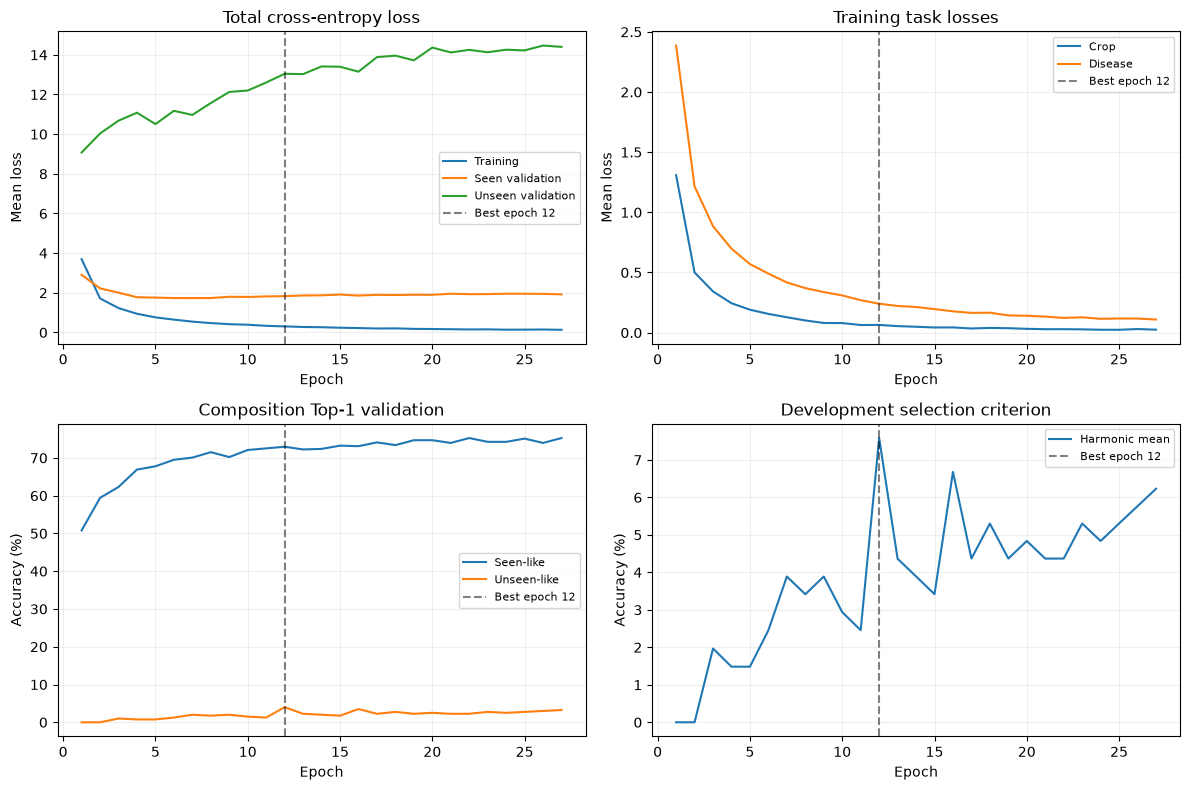

Best development epoch: 12
Saved actual results to: c:\AML\ML_Project\Baseline2\outputs\b2_resnet50_exp09_b1matched_seed42


In [8]:
if RUN_STAGE1:
    if DEVICE.type != "cuda":
        raise RuntimeError("CUDA GPU is required for this run. Stop rather than training for hours on CPU.")
    if (OUTPUT_ROOT / CONFIG["experiment_id"]).exists():
        raise FileExistsError("Experiment folder already exists. Review it; use a new experiment ID for an approved rerun.")
    frames, verified_report = validate_development_splits(SPLIT_DIR)
    candidates = make_candidates(CONFIG["candidate_mode"], CONFIG["candidate_catalog"])
    require_candidate_coverage(candidates, list(frames.values()))
    datasets = {
        name: DPDDataset(frame, IMAGE_ROOT,
                         training_transform(CONFIG) if name == "train_fit" else evaluation_transform(CONFIG["image_size"]))
        for name, frame in frames.items()
    }
    # Check decoding for CSV-listed training/development images only.
    for dataset in datasets.values():
        for path in dataset.paths:
            with Image.open(path) as image:
                image.convert("RGB").load()
    verified_report["image_paths_checked"] = True
    verified_report["image_decoding_checked"] = True
    loaders = {name: make_loader(dataset, CONFIG, shuffle=name == "train_fit")
               for name, dataset in datasets.items()}
    seed_everything(CONFIG["seed"])
    example = next(iter(loaders["val_seen"]))
    assert example["image"].shape[1:] == (3, CONFIG["image_size"], CONFIG["image_size"])
    model, history, metrics, experiment_dir = fit_stage1(
        CONFIG, loaders["train_fit"], loaders["val_seen"], loaders["val_unseen"],
        candidates, verified_report, class_mappings, composition_mapping)
    print("Best development epoch:", metrics["epoch"])
    print("Saved actual results to:", experiment_dir)
else:
    print("Stage 1 disabled. Check IMAGE_ROOT, B1 alignment and CONFIG, then turn RUN_STAGE1 on deliberately.")

## 8. Development error diagnosis — **read-only evaluation**

Optional after Stage 1. Saves one set of seen/unseen predictions and an error-breakdown CSV. **Crop correct but disease wrong** is especially informative; these outputs help evaluate whether the disease head remains the bottleneck. This cannot by itself prove shortcut learning.

In [9]:
RUN_ERROR_ANALYSIS = True
if RUN_ERROR_ANALYSIS:
    checkpoint_path = OUTPUT_ROOT / CONFIG["experiment_id"] / "best_development.pt"
    if not checkpoint_path.is_file():
        raise FileNotFoundError(checkpoint_path)
    diagnostic_model, saved = load_checkpoint(checkpoint_path, DEVICE)
    train_size = int(saved["config"]["image_size"])
    checked_frames, report = validate_development_splits(SPLIT_DIR)
    if report["sha256"] != saved["development_split"]["sha256"]:
        raise RuntimeError("Split hashes do not match selected checkpoint")
    selected_pairs = torch.as_tensor(saved["candidate_pairs"], dtype=torch.long)
    analysis_dir = checkpoint_path.parent
    results = []
    for split_name in ("val_seen", "val_unseen"):
        ds = DPDDataset(checked_frames[split_name], IMAGE_ROOT, evaluation_transform(train_size))
        dl = make_loader(ds, saved["config"], shuffle=False)
        summary, records = evaluate_loader(diagnostic_model, dl, DEVICE, selected_pairs,
                                            saved["config"]["amp"], collect_predictions=True)
        tab = pd.DataFrame(records)
        tab["crop_correct"] = tab.crop_id == tab.predicted_crop_id
        tab["disease_correct"] = tab.disease_id == tab.predicted_disease_id
        tab["crop_only_wrong"] = ~tab.crop_correct & tab.disease_correct
        tab["disease_only_wrong"] = tab.crop_correct & ~tab.disease_correct
        tab["both_wrong"] = ~tab.crop_correct & ~tab.disease_correct
        train_pair_set = set(map(tuple, checked_frames["train_fit"][["crop_id", "disease_id"]].to_numpy().tolist()))
        tab["predicted_pair_seen_in_training"] = [
            (int(cp), int(dp)) in train_pair_set
            for cp, dp in zip(tab.predicted_pair_crop_id, tab.predicted_pair_disease_id)
        ]
        tab.to_csv(analysis_dir / f"{split_name}_error_predictions.csv", index=False)
        results.append({"split": split_name, "n": len(tab),
                        "crop_top1": summary["crop_top1"],
                        "disease_top1": summary["disease_top1"],
                        "composition_top1": summary["composition_top1"],
                        "disease_only_wrong_count": int(tab.disease_only_wrong.sum()),
                        "crop_only_wrong_count": int(tab.crop_only_wrong.sum()),
                        "both_wrong_count": int(tab.both_wrong.sum()),
                        "predicted_pair_seen_in_training_rate": float(tab.predicted_pair_seen_in_training.mean())})
    display(pd.DataFrame(results))
    pd.DataFrame(results).to_csv(analysis_dir / "task_error_breakdown.csv", index=False)
else:
    print("Error analysis disabled; toggle only after a real Stage 1 checkpoint exists.")

,split,n,crop_top1,disease_top1,composition_top1,disease_only_wrong_count,crop_only_wrong_count,both_wrong_count,predicted_pair_seen_in_training_rate
0,val_seen,695,0.889209,0.758273,0.729496,111,20,57,0.935252
1,val_unseen,400,0.705000,0.220000,0.040000,266,72,46,0.852500


## 9. Inference-resolution ablation — **same 224-trained checkpoint, no retraining**

This isolates changing *evaluation resolution* from changing *training resolution*. Run **after** completing a 224 checkpoint. It uses the same saved checkpoint and compares validation at 224 and 320, under the same global candidate list. Save both results without mixing them with trained-at-320 results.

Inference resolution selection is itself validation tuning. Report it as a separate intervention and do not reuse official test results to choose it.

In [10]:
RUN_INFERENCE_RESOLUTION_SWEEP = True
INFERENCE_SWEEP_CHECKPOINT = OUTPUT_ROOT / CONFIG["experiment_id"] / "best_development.pt"
if RUN_INFERENCE_RESOLUTION_SWEEP:
    if not INFERENCE_SWEEP_CHECKPOINT.is_file():
        raise FileNotFoundError(INFERENCE_SWEEP_CHECKPOINT)
    eval_model, parent = load_checkpoint(INFERENCE_SWEEP_CHECKPOINT, DEVICE)
    if parent["config"]["image_size"] != 224:
        raise ValueError("Expected a 224-trained checkpoint for this specific sweep")
    checked_frames, report = validate_development_splits(SPLIT_DIR)
    if report["sha256"] != parent["development_split"]["sha256"]:
        raise RuntimeError("Split hashes changed")
    candidate_pairs = torch.as_tensor(parent["candidate_pairs"], dtype=torch.long)
    compared = []
    for eval_size in (224, 320):
        metrics = {}
        for split in ("val_seen", "val_unseen"):
            dataset = DPDDataset(checked_frames[split], IMAGE_ROOT, evaluation_transform(eval_size))
            loader = make_loader(dataset, parent["config"], shuffle=False)
            metrics[split], _ = evaluate_loader(eval_model, loader, DEVICE, candidate_pairs,
                                                  parent["config"]["amp"])
        g = generalisation_metrics(metrics["val_seen"], metrics["val_unseen"])
        compared.append({"trained_image_size": 224, "evaluated_image_size": eval_size,
                         **{f"seen_{k}": v for k,v in metrics["val_seen"].items() if k.endswith("top1")},
                         **{f"unseen_{k}": v for k,v in metrics["val_unseen"].items() if k.endswith("top1")},
                         **g})
    comparison = pd.DataFrame(compared)
    display(comparison)
    comparison.to_csv(INFERENCE_SWEEP_CHECKPOINT.parent / "inference_resolution_sweep.csv", index=False)
else:
    print("Resolution sweep disabled; no inference has been executed.")

,trained_image_size,evaluated_image_size,seen_crop_top1,seen_disease_top1,seen_composition_top1,unseen_crop_top1,unseen_disease_top1,unseen_composition_top1,composition_harmonic_mean,seen_unseen_gap
0,224,224,0.889209,0.758273,0.729496,0.7050,0.2200,0.0400,0.075841,0.689496
1,224,320,0.879137,0.725180,0.692086,0.6525,0.2375,0.0375,0.071145,0.654586


## 10. Stage 2 — **only after selecting model and settings**

Loads the **selected ResNet-50 Stage 1 checkpoint** and trains on all 8,000 original development images with lower learning rates, which includes former validation images. Stage 2 **must not** report the old validation numbers as independent final validation results. There is no automatic official test invocation.

Screenshot reference: +10 epochs, AdamW, backbone LR 1e-6, head LR 1e-4, cosine annealing. Stage 2 default below is disabled.

In [ ]:
def run_stage2(checkpoint_path, image_root, split_dir, *, approved=False,
               additional_epochs=10, backbone_lr=1e-6, head_lr=1e-4,
               output_dir=None):
    if not approved:
        raise PermissionError("Stage 2 requires explicit approval after development review.")
    if additional_epochs < 1 or int(additional_epochs) != additional_epochs:
        raise ValueError("additional_epochs must be a positive integer")
    checkpoint_path = Path(checkpoint_path)
    parent = torch.load(checkpoint_path, map_location="cpu", weights_only=True)
    if parent["stage"] != 1:
        raise ValueError("Select a Stage 1 development checkpoint")
    config = copy.deepcopy(parent["config"])
    if not (0 < backbone_lr < config["backbone_lr"] and 0 < head_lr < config["head_lr"]):
        raise ValueError("Stage 2 learning rates must be smaller than Stage 1 rates")
    full_frames, report = validate_development_splits(split_dir)
    if report["sha256"] != parent["development_split"]["sha256"]:
        raise ValueError("Split files differ from the selected checkpoint")
    full_frame = pd.concat(full_frames.values(), ignore_index=True)
    assert len(full_frame) == 8000 and full_frame.filename.nunique() == 8000
    config.update({"backbone_lr": backbone_lr, "head_lr": head_lr,
                   "additional_epochs": int(additional_epochs), "scheduler": "CosineAnnealingLR"})
    seed_everything(config["seed"])
    dataset = DPDDataset(full_frame, image_root, training_transform(config))
    for path in dataset.paths:
        with Image.open(path) as image:
            image.convert("RGB").load()
    loader = make_loader(dataset, config, shuffle=True)
    continuation, _ = load_checkpoint(checkpoint_path, DEVICE)
    optimizer = torch.optim.AdamW(continuation.parameter_groups(backbone_lr, head_lr),
                                 weight_decay=config["weight_decay"])
    scaler = torch.amp.GradScaler("cuda", enabled=config["amp"] and DEVICE.type == "cuda")
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=int(additional_epochs))
    destination = (Path(output_dir) if output_dir else
                   checkpoint_path.parent / "stage2_final")
    destination.mkdir(parents=True, exist_ok=False)
    rows = []
    started = time.perf_counter()
    for epoch in range(1, int(additional_epochs) + 1):
        losses = train_one_epoch(continuation, loader, optimizer, scaler, DEVICE, config["amp"],
                                 config["crop_loss_weight"], config["disease_loss_weight"])
        rows.append({"additional_epoch": epoch, "backbone_lr": optimizer.param_groups[0]["lr"],
                     "head_lr": optimizer.param_groups[1]["lr"], **losses})
        scheduler.step()
        pd.DataFrame(rows).to_csv(destination / "full_data_history.csv", index=False)
        print(f"Stage 2 epoch {epoch}: loss {losses['total_loss']:.4f}")
    atomic_checkpoint({"stage": 2, "epoch": int(additional_epochs),
        "model_state": continuation.state_dict(), "optimizer_state": optimizer.state_dict(),
        "scheduler_state": scheduler.state_dict(),
        "scaler_state": scaler.state_dict(), "config": config,
        "candidate_pairs": parent["candidate_pairs"], "class_mappings": parent["class_mappings"],
        "composition_mapping": parent["composition_mapping"], "development_split": report,
        "parent_checkpoint": str(checkpoint_path), "parent_checkpoint_sha256": sha256_file(checkpoint_path),
        "parent_best_epoch": parent["epoch"], "full_training_count": len(full_frame),
        "environment": environment_details(), "training_seconds": time.perf_counter() - started,
        "former_validation_is_independent": False}, destination / "final_full_data.pt")
    continuation.eval()
    print("Stage 2 complete. No official testing has been run.")
    return continuation, destination

In [ ]:
RUN_STAGE2 = False
CHOSEN_DEVELOPMENT_CHECKPOINT = OUTPUT_ROOT / CONFIG["experiment_id"] / "best_development.pt"
if RUN_STAGE2:
    final_model, final_directory = run_stage2(
        CHOSEN_DEVELOPMENT_CHECKPOINT, IMAGE_ROOT, SPLIT_DIR,
        approved=True, additional_epochs=10,
        backbone_lr=1e-6, head_lr=1e-4)
else:
    print("Stage 2 is disabled. Select checkpoint and confirm B1 matching before enabling it.")

## 11. Experiment decisions and fairness limitations

- Exp09 aligns the principal training settings and preprocessing with Amanda's B1 **higher_decay** configuration. Checkpoint selection still necessarily differs: B1 selects crop and disease models separately using individual task development HM; B2 selects a single shared checkpoint using composition HM.
- The change from Exp08 is **not a weight-decay-only ablation**: weight decay, interpolation and workers were updated together to match the B1 pipeline. To isolate weight decay, use a separate single-variable ablation.
- The `num_workers=4` benchmark measured data loading, not full training time. Record actual epoch time for this run.
- Never compare this Stage 1 development result with B1 **official test** accuracy. Evaluate both methods on the same development split for comparison; official test remains a one-time separate step under the lecturer's protocol.
- Section 8 and Section 9 are optional **read-only development diagnostics**. Section 10 (Stage 2) is disabled; its current final-checkpoint policy does not yet match Amanda's per-epoch top-1 checkpoint selection and should be revised **before Stage 2**.
- Multi-seed trials belong in new experiment IDs, e.g. `b2_resnet50_b1matched_seed123`, once one fixed configuration has been agreed.
